# 04 学習済みCNN：conv2 TT cores-only fine-tuning

03で固定tensorizationのrank sweepを行い、rank 12・16・20をparameter予算の代表候補、rank 24を圧縮直後にdense accuracyへほぼ回復した比較対象として得ました。

04では新しい分解手法を導入せず、各rankの`conv2.cores.*`だけを更新します。目的は、残りのCNNを固定したままTT-Conv自身の学習によって分類性能がどこまで回復するかを確認することです。実装はすべて完成コードです。

## 1. 実験条件と選択規則

固定するtensorizationは03と同じです。

$$
(m_1,m_2,m_3)=(4,4,4),\qquad (n_1,n_2,n_3)=(6,6,8)
$$

比較するrequested rank upper boundは`12, 16, 20, 24`です。rank 12・16・20は03のPareto knee周辺から得た予算候補で、rank 24は自動knee候補ではなく、圧縮直後のvalidation accuracyがdenseモデルにほぼ戻った**accuracy-recovery reference**です。

各trialは同じdense checkpointからTT-SVDをやり直し、同じseedと同じmini-batch順序で開始します。学習可能parameterは`conv2.cores.*`だけです。`conv2.bias`、`conv1`、`fc1`、`fc2`は固定します。

checkpointはfine-tuning監視用5,000件のcross-entropy lossだけで選びます。epoch 0も最初のbest候補に含めます。rank比較用5,000件のaccuracy・denseモデルとのprediction agreement・logits RMSEは、epoch 0と選択済みcheckpointだけで測り、checkpoint選択には使いません。test 10,000件はロード後に件数だけ確認し、評価しません。

In [7]:
from __future__ import annotations

import copy
import json
import math
import os
import sys
import time
from pathlib import Path

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from torch import nn
from torch.utils.data import DataLoader

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        project_root = candidate
        break
else:
    raise RuntimeError("src/nn_compressionが見つかりません。")

from nn_compression.compression import (
    dense_to_tt_matrix_cores,
    tt_linear_forward,
    tt_matrix_num_parameters,
    tt_matrix_ranks,
)
from nn_compression.datasets import (
    get_fashion_mnist_datasets,
    split_fashion_mnist_dataset,
)
from nn_compression.metrics import agreement, count_parameters, logits_rmse
from nn_compression.models import FashionMNISTCNN
from nn_compression.training import evaluate, train_one_epoch
from nn_compression.utils import make_torch_generator, set_seed

SEED = 0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32
OUT_MODES = (4, 4, 4)
IN_MODES = (6, 6, 8)
RANK_CANDIDATES = (12, 16, 20, 24)
RANK_ROLES = {
    12: "pareto_aggressive",
    16: "pareto_balanced",
    20: "pareto_conservative",
    24: "accuracy_recovery_reference",
}
SPLIT_LENGTHS = (50_000, 5_000, 5_000)
TRAIN_BATCH_SIZE = 64
VALIDATION_BATCH_SIZE = 256
LEARNING_RATE = 1e-3
MAX_EPOCHS = 50
PATIENCE = 5
MIN_DELTA = 1e-4
EPOCH0_METRIC_ATOL = 1e-4
SAVE_RESULTS = True

set_seed(SEED)
print("project root:", project_root)
print("device / dtype:", DEVICE, DTYPE)
print("rank candidates:", RANK_CANDIDATES)

project root: D:\dev\nn-compression-svd-dmrg
device / dtype: cuda torch.float32
rank candidates: (12, 16, 20, 24)


## 2. checkpointとデータ分割

03と同じ60,000件を、同じseedで50,000／5,000／5,000へ分割します。

- `train_dataset`：TT coresの更新に使用する50,000件。
- `finetuning_monitor_dataset`：early stoppingとcheckpoint選択だけに使う5,000件。baseline学習時には使用済みです。
- `rank_validation_dataset`：各rankのepoch 0と選択済みcheckpointを比較する5,000件。02・03のvalidationと同じindexです。
- `test_dataset_reserved`：最終評価まで保持する10,000件。04では評価しません。

各rankの学習用DataLoaderはtrialごとに同じseedのGeneratorから新しく作り、同じmini-batch順序を再現します。

In [8]:
checkpoint_path = (
    project_root / "models" / "10_svd" / "30_fashion_mnist_cnn"
    / "01_cnn_baseline" / "fashion_mnist_cnn_baseline.pt"
)
data_dir = project_root / "data"
results_dir = (
    project_root / "results" / "30_tt_mps"
    / "20_fashion_mnist_cnn"
    / "04_pretrained_cnn_conv2_tt_cores_only_finetuning"
)
models_dir = (
    project_root / "models" / "30_tt_mps"
    / "20_fashion_mnist_cnn"
    / "04_pretrained_cnn_conv2_tt_cores_only_finetuning"
)
rank_sweep_03_dir = (
    project_root / "results" / "30_tt_mps"
    / "20_fashion_mnist_cnn"
    / "03_pretrained_cnn_conv2_tt_rank_sweep"
)
rank_sweep_03_path = rank_sweep_03_dir / "rank_sweep_results.csv"
split_indices_03_path = rank_sweep_03_dir / "split_indices.pt"

if not checkpoint_path.is_file():
    raise FileNotFoundError(f"baseline checkpointが見つかりません: {checkpoint_path}")

checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
baseline_state = checkpoint["model_state_dict"]
dense_model = FashionMNISTCNN().to(device=DEVICE, dtype=DTYPE)
dense_model.load_state_dict(baseline_state)
dense_model.eval()
dense_state_reference = {
    name: value.detach().clone()
    for name, value in dense_model.state_dict().items()
}

full_train_dataset, test_dataset_reserved = get_fashion_mnist_datasets(
    data_dir, download=True
)
_, validation_02_reproduced = split_fashion_mnist_dataset(
    full_train_dataset, (55_000, 5_000), seed=SEED
)
train_dataset, finetuning_monitor_dataset, rank_validation_dataset = (
    split_fashion_mnist_dataset(
        full_train_dataset, SPLIT_LENGTHS, seed=SEED
    )
)

train_indices = list(train_dataset.indices)
monitor_indices = list(finetuning_monitor_dataset.indices)
rank_validation_indices = list(rank_validation_dataset.indices)
assert rank_validation_indices == list(validation_02_reproduced.indices)
assert set(train_indices).isdisjoint(monitor_indices)
assert set(train_indices).isdisjoint(rank_validation_indices)
assert set(monitor_indices).isdisjoint(rank_validation_indices)
assert len(set(train_indices + monitor_indices + rank_validation_indices)) == 60_000
assert len(test_dataset_reserved) == 10_000

if not rank_sweep_03_path.is_file() or not split_indices_03_path.is_file():
    raise FileNotFoundError("03のrank sweep結果またはsplit indexが見つかりません。")
df_rank_sweep_03 = pd.read_csv(rank_sweep_03_path)
split_indices_03 = torch.load(
    split_indices_03_path, map_location="cpu", weights_only=True
)
assert train_indices == list(split_indices_03["train_indices"])
assert monitor_indices == list(split_indices_03["finetuning_monitor_indices"])
assert rank_validation_indices == list(split_indices_03["rank_validation_indices"])
reference_ranks_03 = set(
    df_rank_sweep_03["requested_rank_upper_bound"].astype(int)
)
assert set(RANK_CANDIDATES).issubset(reference_ranks_03)

monitor_loader = DataLoader(
    finetuning_monitor_dataset, batch_size=VALIDATION_BATCH_SIZE, shuffle=False
)
rank_validation_loader = DataLoader(
    rank_validation_dataset, batch_size=VALIDATION_BATCH_SIZE, shuffle=False
)
criterion = nn.CrossEntropyLoss()
dense_rank_validation_loss, dense_rank_validation_accuracy = evaluate(
    dense_model, rank_validation_loader, criterion, DEVICE
)
dense_model_parameters = count_parameters(dense_model)
assert dense_model_parameters == 421_642
assert abs(dense_rank_validation_accuracy - 0.9194) <= 1 / len(rank_validation_dataset)
print("dense rank-validation accuracy:", dense_rank_validation_accuracy)
print("test size (not evaluated):", len(test_dataset_reserved))

dense rank-validation accuracy: 0.9194
test size (not evaluated): 10000


## 3. 02・03で検証した`TTConv2d`

`TTConv2d`はdenseなkernel parameterを保持せず、`nn.ParameterList`に登録したTT coresを直接縮約して畳み込みを計算します。04ではこの層の実装を学習課題に戻さず、02・03と同じ契約を再利用します。

In [9]:
def _as_pair(
    value: int | tuple[int, int],
    name: str,
    minimum: int,
) -> tuple[int, int]:
    """Conv2d設定を2整数のtupleへ正規化する。

    Args:
        value: 1個の整数、または高さ・幅を表す2整数。
        name: エラーメッセージに表示する設定名。
        minimum: 各要素に許す最小値。

    Returns:
        高さ・幅の順に正規化した2整数のtuple。
    """
    if isinstance(value, int) and not isinstance(value, bool):
        value = (value, value)
    if not isinstance(value, tuple) or len(value) != 2:
        raise TypeError(f"{name} must be an int or a tuple of two ints.")
    if not all(isinstance(v, int) and not isinstance(v, bool) for v in value):
        raise TypeError(f"{name} must contain integers.")
    if any(v < minimum for v in value):
        raise ValueError(f"Each value in {name} must be >= {minimum}.")
    return value


class TTConv2d(nn.Module):
    """TT-matrix coresをparameterとして保持する2次元畳み込み層。"""

    def __init__(
        self,
        cores: list[torch.Tensor],
        bias: torch.Tensor | None,
        in_channels: int,
        out_channels: int,
        kernel_size: int | tuple[int, int],
        stride: int | tuple[int, int],
        padding: int | tuple[int, int],
        dilation: int | tuple[int, int],
        groups: int,
        padding_mode: str,
        out_modes: tuple[int, ...],
        in_modes: tuple[int, ...],
    ) -> None:
        """TT coresと元Conv2dの設定から層を初期化する。

        Args:
            cores: TT-matrixを構成する4階Tensorの列。
            bias: 出力channelごとのbias。
            in_channels: 入力channel数。
            out_channels: 出力channel数。
            kernel_size: 畳み込みkernelの高さと幅。
            stride: 畳み込みのstride。
            padding: zero paddingの大きさ。
            dilation: kernel要素間の間隔。
            groups: 入出力channelのgroup数。今回は1のみ。
            padding_mode: padding方式。今回はzerosのみ。
            out_modes: 出力channelを分解するphysical modes。
            in_modes: 入力patch幅を分解するphysical modes。

        Returns:
            None。初期化したcoresとbiasはparameterとして登録される。
        """
        super().__init__()
        kernel_size = _as_pair(kernel_size, "kernel_size", 1)
        stride = _as_pair(stride, "stride", 1)
        padding = _as_pair(padding, "padding", 0)
        dilation = _as_pair(dilation, "dilation", 1)
        if groups != 1 or padding_mode != "zeros":
            raise NotImplementedError("Only groups=1 and zero padding are supported.")
        if not (len(cores) == len(out_modes) == len(in_modes)):
            raise ValueError("The numbers of cores and modes must match.")
        if math.prod(out_modes) != out_channels:
            raise ValueError("The product of out_modes must equal out_channels.")
        if math.prod(in_modes) != in_channels * math.prod(kernel_size):
            raise ValueError("The product of in_modes must equal the patch width.")
        for index, core in enumerate(cores):
            if core.ndim != 4 or tuple(core.shape[1:3]) != (out_modes[index], in_modes[index]):
                raise ValueError(f"core {index} has incompatible physical modes.")
        if cores[0].shape[0] != 1 or cores[-1].shape[-1] != 1:
            raise ValueError("Boundary ranks must be 1.")
        for left, right in zip(cores[:-1], cores[1:]):
            if left.shape[-1] != right.shape[0]:
                raise ValueError("Adjacent bond dimensions must match.")

        self.cores = nn.ParameterList([
            nn.Parameter(core.detach().clone()) for core in cores
        ])
        self.bias = (
            nn.Parameter(bias.detach().clone()) if bias is not None else None
        )
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.stride = stride
        self.padding = padding
        self.dilation = dilation
        self.groups = groups
        self.padding_mode = padding_mode
        self.out_modes = tuple(out_modes)
        self.in_modes = tuple(in_modes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """dense kernelを再構成せず、patchへTTLinearを適用する。

        Args:
            x: shapeが`(batch, in_channels, height, width)`の入力。

        Returns:
            TT-Conv後の4階Tensor。
        """
        batch_size, _, input_height, input_width = x.shape
        output_height = (
            input_height + 2 * self.padding[0]
            - self.dilation[0] * (self.kernel_size[0] - 1) - 1
        ) // self.stride[0] + 1
        output_width = (
            input_width + 2 * self.padding[1]
            - self.dilation[1] * (self.kernel_size[1] - 1) - 1
        ) // self.stride[1] + 1
        unfolded = F.unfold(
            x, kernel_size=self.kernel_size, dilation=self.dilation,
            padding=self.padding, stride=self.stride
        )
        patch_width = self.in_channels * math.prod(self.kernel_size)
        patch_matrix = unfolded.permute(0, 2, 1).reshape(-1, patch_width)
        patch_output = tt_linear_forward(
            patch_matrix, list(self.cores), self.out_modes, self.in_modes,
            bias=self.bias
        )
        return patch_output.reshape(
            batch_size, output_height, output_width, self.out_channels
        ).permute(0, 3, 1, 2)

## 4. rankごとのepoch 0モデルを作る

`build_tt_cores_only_model`は、必ず同じdense `conv2.weight`からTT-SVDし、独立したCNNの`conv2`だけを置換します。出力は、TTモデル、actual ranks、core parameter数です。

期待する状態は次のとおりです。

- 学習可能parameter名は`conv2.cores.0`、`conv2.cores.1`、`conv2.cores.2`だけ。
- `conv2.bias`とconv2以外のparameterはdense checkpointと完全一致したまま固定。
- denseな`conv2.weight`はTTモデルに存在しない。
- モデルparameter数は$421{,}642-18{,}432+P_{\mathrm{cores}}$。

In [10]:
def build_tt_cores_only_model(
    requested_rank: int,
) -> tuple[nn.Module, tuple[int, ...], int]:
    """dense checkpointからTT cores-only学習用CNNを作る。

    Args:
        requested_rank: 2本の内部bondに共通して与えるrank上限。

    Returns:
        TT-Convへ置換したCNN、actual ranks、TT core parameter数。
    """
    model = FashionMNISTCNN().to(device=DEVICE, dtype=DTYPE)
    model.load_state_dict(baseline_state)
    dense_conv2 = model.conv2
    weight_matrix = dense_conv2.weight.detach().reshape(64, 288)
    cores = dense_to_tt_matrix_cores(
        weight_matrix, OUT_MODES, IN_MODES, max_rank=requested_rank
    )
    actual_ranks = tt_matrix_ranks(cores)
    core_parameters = tt_matrix_num_parameters(cores)
    model.conv2 = TTConv2d(
        cores=cores,
        bias=dense_conv2.bias,
        in_channels=dense_conv2.in_channels,
        out_channels=dense_conv2.out_channels,
        kernel_size=dense_conv2.kernel_size,
        stride=dense_conv2.stride,
        padding=dense_conv2.padding,
        dilation=dense_conv2.dilation,
        groups=dense_conv2.groups,
        padding_mode=dense_conv2.padding_mode,
        out_modes=OUT_MODES,
        in_modes=IN_MODES,
    )

    for parameter in model.parameters():
        parameter.requires_grad_(False)
    for core in model.conv2.cores:
        core.requires_grad_(True)

    trainable_names = {
        name for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }
    assert trainable_names == {
        "conv2.cores.0", "conv2.cores.1", "conv2.cores.2"
    }
    assert not hasattr(model.conv2, "weight")
    assert torch.equal(model.conv2.bias.detach(), baseline_state["conv2.bias"].to(DEVICE))
    for name, value in model.state_dict().items():
        if not name.startswith("conv2."):
            torch.testing.assert_close(value, dense_state_reference[name])
    expected_parameters = dense_model_parameters - 18_432 + core_parameters
    assert count_parameters(model) == expected_parameters
    return model, actual_ranks, core_parameters


construction_summary = []
for requested_rank in RANK_CANDIDATES:
    check_model, actual_ranks, core_parameters = build_tt_cores_only_model(
        requested_rank
    )
    construction_summary.append({
        "requested_rank": requested_rank,
        "rank_role": RANK_ROLES[requested_rank],
        "actual_ranks": actual_ranks,
        "tt_core_parameters": core_parameters,
        "model_parameters": count_parameters(check_model),
        "trainable_parameters": sum(
            p.numel() for p in check_model.parameters() if p.requires_grad
        ),
    })
del check_model
df_construction = pd.DataFrame(construction_summary)
display(df_construction)

,requested_rank,rank_role,actual_ranks,tt_core_parameters,model_parameters,trainable_parameters
0,12,pareto_aggressive,"(1, 12, 12, 1)",4128,407338,4128
1,16,pareto_balanced,"(1, 16, 16, 1)",7040,410250,7040
2,20,pareto_conservative,"(1, 20, 20, 1)",10720,413930,10720
3,24,accuracy_recovery_reference,"(1, 24, 24, 1)",15168,418378,15168


## 5. epoch 0を含むearly stopping

epoch 0の監視用lossを最初のbest lossとします。epoch $t$の監視用lossを$L_t$、現在のbestを$L_{\mathrm{best}}$とすると、更新条件は

$$
L_{\mathrm{best}}-L_t>\delta,\qquad \delta=10^{-4}
$$

です。改善しないepochが5回続いたら停止します。学習曲線にはtrainと監視用validationのloss・accuracyを保存します。`seconds_this_epoch`と`cumulative_training_seconds`は`train_one_epoch`だけの時間で、監視用評価時間を含みません。agreementとlogits RMSEは高コストな全validation比較なので、epoch 0と選択済みcheckpointだけで測ります。したがって、これらは学習曲線ではなく前後比較表に入ります。

In [11]:
def evaluate_rank_state(
    model: nn.Module,
) -> dict[str, float]:
    """rank比較用5,000件で3種類の指標を測る。

    Args:
        model: epoch 0または選択済みのTT-Conv CNN。

    Returns:
        loss、accuracy、prediction agreement、logits RMSEの辞書。
    """
    loss, accuracy = evaluate(
        model, rank_validation_loader, criterion, DEVICE
    )
    return {
        "rank_validation_loss": loss,
        "rank_validation_accuracy": accuracy,
        "prediction_agreement": agreement(
            dense_model, model, rank_validation_loader, DEVICE
        ),
        "logits_rmse": logits_rmse(
            dense_model, model, rank_validation_loader, DEVICE
        ),
    }


def clone_state_dict(model: nn.Module) -> dict[str, torch.Tensor]:
    """現在のstateを後の復元用に独立cloneする。

    Args:
        model: parameterとbufferを保存するモデル。

    Returns:
        state名から独立cloneしたTensorへの辞書。
    """
    return {
        name: value.detach().clone()
        for name, value in model.state_dict().items()
    }


def run_finetuning_trial(
    requested_rank: int,
) -> tuple[dict[str, object], list[dict[str, object]], nn.Module, list[dict[str, object]]]:
    """1 rankをepoch 0から学習し、監視用lossで選択する。

    Args:
        requested_rank: TT-SVDとtrialを行う共通rank上限。

    Returns:
        選択結果、epoch履歴、選択済みモデル、parameter検証記録。
    """
    set_seed(SEED)
    model, actual_ranks, core_parameters = build_tt_cores_only_model(
        requested_rank
    )
    initial_state = clone_state_dict(model)
    trainable_parameters = [
        parameter for parameter in model.parameters() if parameter.requires_grad
    ]
    optimizer = torch.optim.Adam(trainable_parameters, lr=LEARNING_RATE)
    optimizer_parameter_ids = {
        id(parameter) for group in optimizer.param_groups
        for parameter in group["params"]
    }
    assert optimizer_parameter_ids == {id(parameter) for parameter in trainable_parameters}

    train_loader = DataLoader(
        train_dataset, batch_size=TRAIN_BATCH_SIZE, shuffle=True,
        generator=make_torch_generator(SEED)
    )
    epoch0_monitor_loss, epoch0_monitor_accuracy = evaluate(
        model, monitor_loader, criterion, DEVICE
    )
    epoch0_rank_metrics = evaluate_rank_state(model)
    reference_03 = df_rank_sweep_03.loc[
        df_rank_sweep_03["requested_rank_upper_bound"] == requested_rank
    ].iloc[0]
    assert abs(
        epoch0_rank_metrics["rank_validation_accuracy"]
        - float(reference_03["validation_accuracy"])
    ) <= 1 / len(rank_validation_dataset)
    assert abs(
        epoch0_rank_metrics["prediction_agreement"]
        - float(reference_03["prediction_agreement"])
    ) <= 1 / len(rank_validation_dataset)
    assert abs(
        epoch0_rank_metrics["logits_rmse"]
        - float(reference_03["logits_rmse"])
    ) <= EPOCH0_METRIC_ATOL
    best_loss = epoch0_monitor_loss
    best_epoch = 0
    best_state = clone_state_dict(model)
    patience_counter = 0
    cumulative_seconds = 0.0
    history = [{
        "requested_rank": requested_rank,
        "rank_role": RANK_ROLES[requested_rank],
        "epoch": 0,
        "train_loss": np.nan,
        "train_accuracy": np.nan,
        "monitor_loss": epoch0_monitor_loss,
        "monitor_accuracy": epoch0_monitor_accuracy,
        "cumulative_training_seconds": 0.0,
        "seconds_this_epoch": 0.0,
        "best_updated": True,
        "patience_counter": 0,
    }]

    for epoch in range(1, MAX_EPOCHS + 1):
        start = time.perf_counter()
        train_loss, train_accuracy = train_one_epoch(
            model, train_loader, criterion, optimizer, DEVICE
        )
        seconds_this_epoch = time.perf_counter() - start
        cumulative_seconds += seconds_this_epoch
        monitor_loss, monitor_accuracy = evaluate(
            model, monitor_loader, criterion, DEVICE
        )
        best_updated = best_loss - monitor_loss > MIN_DELTA
        if best_updated:
            best_loss = monitor_loss
            best_epoch = epoch
            best_state = clone_state_dict(model)
            patience_counter = 0
        else:
            patience_counter += 1
        history.append({
            "requested_rank": requested_rank,
            "rank_role": RANK_ROLES[requested_rank],
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "monitor_loss": monitor_loss,
            "monitor_accuracy": monitor_accuracy,
            "cumulative_training_seconds": cumulative_seconds,
            "seconds_this_epoch": seconds_this_epoch,
            "best_updated": best_updated,
            "patience_counter": patience_counter,
        })
        if patience_counter >= PATIENCE:
            break

    executed_epochs = history[-1]["epoch"]
    model.load_state_dict(best_state)
    selected_monitor_loss, selected_monitor_accuracy = evaluate(
        model, monitor_loader, criterion, DEVICE
    )
    assert math.isclose(
        selected_monitor_loss, best_loss, rel_tol=0.0, abs_tol=1e-12
    )
    selected_rank_metrics = evaluate_rank_state(model)
    for state_name, state_value in model.state_dict().items():
        if not state_name.startswith("conv2.cores."):
            assert torch.equal(
                state_value.detach(), initial_state[state_name]
            ), f"Frozen state changed: {state_name}"
    verification = []
    for name, parameter in model.named_parameters():
        exact_equal = torch.equal(parameter.detach(), initial_state[name])
        if not parameter.requires_grad:
            assert exact_equal, f"Frozen parameter changed: {name}"
        verification.append({
            "requested_rank": requested_rank,
            "parameter_name": name,
            "is_trainable": bool(parameter.requires_grad),
            "numel": parameter.numel(),
            "exact_equal": exact_equal,
            "max_abs_change": (
                parameter.detach() - initial_state[name]
            ).abs().max().item(),
        })

    record = {
        "requested_rank": requested_rank,
        "rank_role": RANK_ROLES[requested_rank],
        "actual_ranks": actual_ranks,
        "tt_core_parameters": core_parameters,
        "model_parameters": count_parameters(model),
        "model_compression_ratio": dense_model_parameters / count_parameters(model),
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "epoch0_monitor_loss": epoch0_monitor_loss,
        "selected_monitor_loss": selected_monitor_loss,
        "selected_monitor_accuracy": selected_monitor_accuracy,
        "epoch0_rank_validation_accuracy": epoch0_rank_metrics["rank_validation_accuracy"],
        "selected_rank_validation_accuracy": selected_rank_metrics["rank_validation_accuracy"],
        "accuracy_change": (
            selected_rank_metrics["rank_validation_accuracy"]
            - epoch0_rank_metrics["rank_validation_accuracy"]
        ),
        "epoch0_prediction_agreement": epoch0_rank_metrics["prediction_agreement"],
        "selected_prediction_agreement": selected_rank_metrics["prediction_agreement"],
        "agreement_change": (
            selected_rank_metrics["prediction_agreement"]
            - epoch0_rank_metrics["prediction_agreement"]
        ),
        "epoch0_logits_rmse": epoch0_rank_metrics["logits_rmse"],
        "selected_logits_rmse": selected_rank_metrics["logits_rmse"],
        "logits_rmse_change": (
            selected_rank_metrics["logits_rmse"]
            - epoch0_rank_metrics["logits_rmse"]
        ),
        "selected_epoch": best_epoch,
        "executed_epochs": executed_epochs,
        "cumulative_training_seconds": cumulative_seconds,
        "mean_seconds_per_executed_epoch": (
            cumulative_seconds / executed_epochs if executed_epochs else 0.0
        ),
        "selection_criterion": "finetuning_monitor_loss",
        "update_scope": "tt_cores_only",
    }
    return record, history, model, verification

## 6. 4つのrankを同一条件でfine-tuningする

各trialは独立にepoch 0モデルと学習用DataLoaderを作ります。`selected_epoch = 0`は失敗ではなく、追加学習後の監視用lossがepoch 0を十分に上回れなかったことを意味します。特にrank 24では、この結果を許容します。

In [12]:
comparison_records = []
history_records = []
parameter_verification_records = []
selected_models = {}

for requested_rank in RANK_CANDIDATES:
    print(f"\n=== rank {requested_rank}: {RANK_ROLES[requested_rank]} ===")
    record, history, selected_model, verification = run_finetuning_trial(
        requested_rank
    )
    comparison_records.append(record)
    history_records.extend(history)
    parameter_verification_records.extend(verification)
    selected_models[requested_rank] = selected_model
    print(
        "selected epoch / executed epochs:",
        record["selected_epoch"], "/", record["executed_epochs"]
    )

df_finetuning_comparison = (
    pd.DataFrame(comparison_records)
    .sort_values("requested_rank")
    .reset_index(drop=True)
)
df_finetuning_history = (
    pd.DataFrame(history_records)
    .sort_values(["requested_rank", "epoch"])
    .reset_index(drop=True)
)
df_parameter_verification = (
    pd.DataFrame(parameter_verification_records)
    .sort_values(["requested_rank", "parameter_name"])
    .reset_index(drop=True)
)
display(df_finetuning_comparison.round(6))


=== rank 12: pareto_aggressive ===
selected epoch / executed epochs: 14 / 19

=== rank 16: pareto_balanced ===
selected epoch / executed epochs: 8 / 13

=== rank 20: pareto_conservative ===
selected epoch / executed epochs: 9 / 14

=== rank 24: accuracy_recovery_reference ===
selected epoch / executed epochs: 9 / 14


,requested_rank,rank_role,actual_ranks,tt_core_parameters,model_parameters,model_compression_ratio,trainable_parameters,epoch0_monitor_loss,selected_monitor_loss,selected_monitor_accuracy,...,agreement_change,epoch0_logits_rmse,selected_logits_rmse,logits_rmse_change,selected_epoch,executed_epochs,cumulative_training_seconds,mean_seconds_per_executed_epoch,selection_criterion,update_scope
0,12,pareto_aggressive,"(1, 12, 12, 1)",4128,407338,1.035116,4128,0.733657,0.168096,0.9380,...,0.2530,4.575319,2.363685,-2.211634,14,19,128.853391,6.781757,finetuning_monitor_loss,tt_cores_only
1,16,pareto_balanced,"(1, 16, 16, 1)",7040,410250,1.027768,7040,0.426510,0.165511,0.9362,...,0.1088,3.259954,2.620690,-0.639264,8,13,94.987348,7.306719,finetuning_monitor_loss,tt_cores_only
2,20,pareto_conservative,"(1, 20, 20, 1)",10720,413930,1.018631,10720,0.246614,0.166412,0.9356,...,0.0172,1.965624,2.456761,0.491137,9,14,123.055622,8.789687,finetuning_monitor_loss,tt_cores_only
3,24,accuracy_recovery_reference,"(1, 24, 24, 1)",15168,418378,1.007802,15168,0.185378,0.164208,0.9374,...,-0.0200,0.725765,2.572105,1.846340,9,14,115.718862,8.265633,finetuning_monitor_loss,tt_cores_only


## 7. 更新範囲と実験境界を検証する

選択済みcheckpointについて、固定parameterがepoch 0から完全に変化していないこと、TT構造とparameter数が維持されていることを確認します。また、履歴にepoch 0が含まれ、rank-validation指標がcheckpoint選択列に使われていないことを確認します。

In [13]:
assert set(df_finetuning_comparison["requested_rank"]) == set(RANK_CANDIDATES)
assert set(df_finetuning_comparison["update_scope"]) == {"tt_cores_only"}
assert set(df_finetuning_comparison["selection_criterion"]) == {"finetuning_monitor_loss"}
assert df_finetuning_comparison["selected_rank_validation_accuracy"].between(0, 1).all()
assert df_finetuning_comparison["selected_prediction_agreement"].between(0, 1).all()
assert (df_finetuning_comparison["selected_logits_rmse"] >= 0).all()
assert (
    df_finetuning_history.groupby("requested_rank")["epoch"].min() == 0
).all()
assert (
    df_parameter_verification.loc[
        ~df_parameter_verification["is_trainable"], "exact_equal"
    ].all()
)
for requested_rank, model in selected_models.items():
    trainable_names = {
        name for name, parameter in model.named_parameters()
        if parameter.requires_grad
    }
    assert trainable_names == {
        "conv2.cores.0", "conv2.cores.1", "conv2.cores.2"
    }
    row = df_finetuning_comparison.loc[
        df_finetuning_comparison["requested_rank"] == requested_rank
    ].iloc[0]
    assert tt_matrix_ranks(list(model.conv2.cores)) == tuple(row["actual_ranks"])
    assert count_parameters(model) == int(row["model_parameters"])

assert len(test_dataset_reserved) == 10_000
assert not any("test" in column for column in df_finetuning_comparison.columns)
print("fine-tuning verification: OK")

fine-tuning verification: OK


## 8. 学習前後と学習曲線を可視化する

accuracy、agreement、logits RMSEは意味が異なるため別々の図にします。accuracy図だけにdense baselineを黒い破線で表示します。学習曲線はcheckpoint選択に用いたmonitor lossと、参考としてtrain lossを表示します。

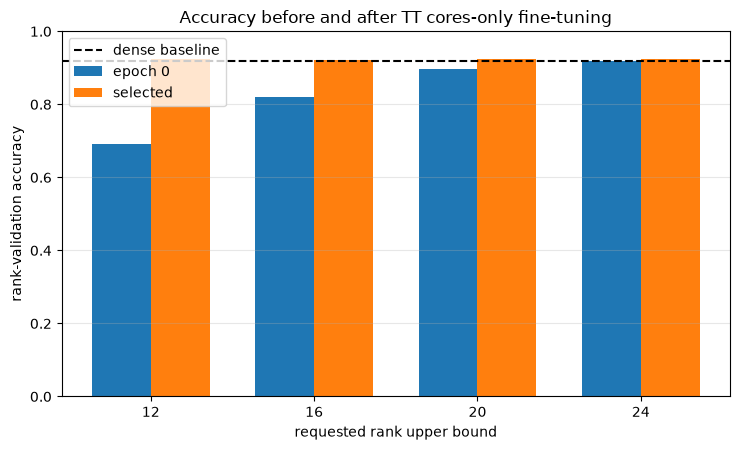

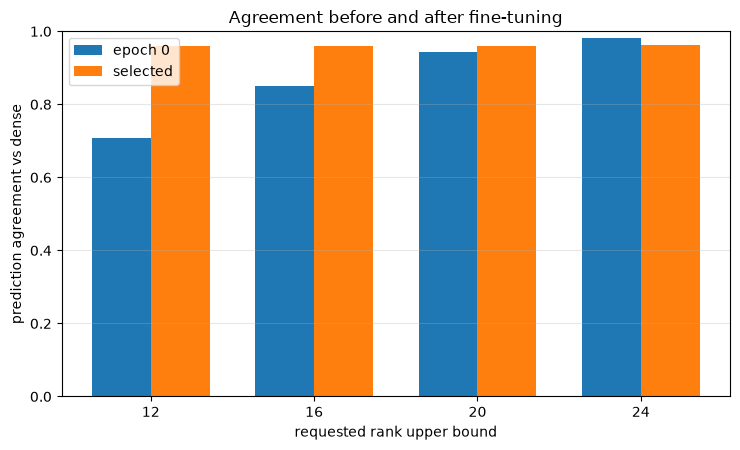

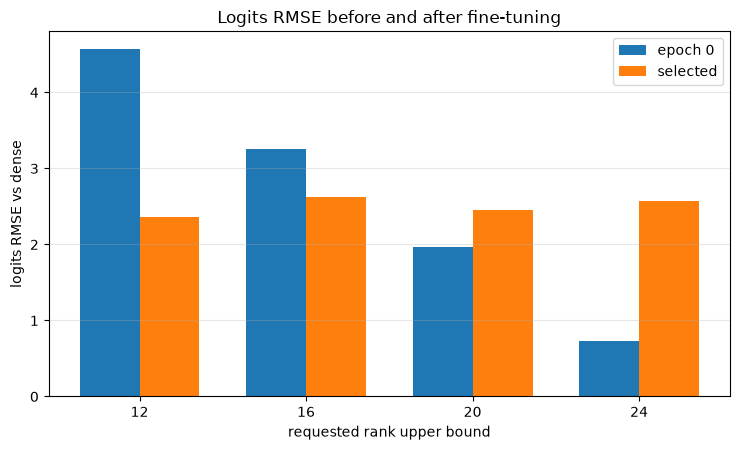

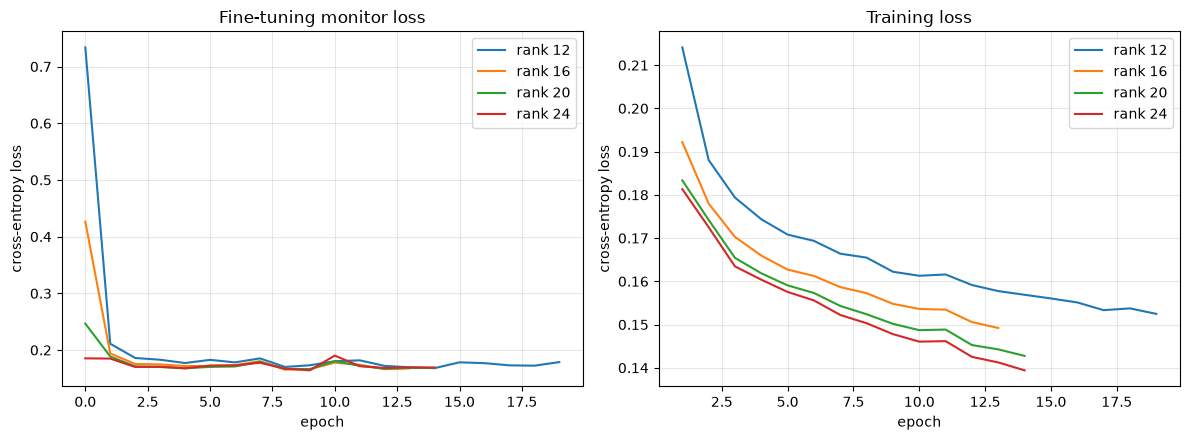

In [14]:
ranks = list(RANK_CANDIDATES)
x = np.arange(len(ranks))
width = 0.36

def plot_before_after(
    before_column: str,
    after_column: str,
    ylabel: str,
    title: str,
    *,
    ylim: tuple[float, float] | None = None,
    baseline: float | None = None,
) -> plt.Figure:
    """rankごとのepoch 0と選択済み値を並べる。

    Args:
        before_column: epoch 0の値を保持する列名。
        after_column: 選択済みcheckpointの値を保持する列名。
        ylabel: 縦軸ラベル。
        title: Figureのタイトル。
        ylim: 縦軸範囲。Noneなら自動設定。
        baseline: accuracy図に加えるdense基準線。

    Returns:
        作成したmatplotlib Figure。
    """
    frame = df_finetuning_comparison.sort_values("requested_rank")
    fig, ax = plt.subplots(figsize=(7.5, 4.6))
    ax.bar(x - width / 2, frame[before_column], width, label="epoch 0")
    ax.bar(x + width / 2, frame[after_column], width, label="selected")
    if baseline is not None:
        ax.axhline(baseline, color="black", linestyle="--", label="dense baseline")
    ax.set_xticks(x, [str(rank) for rank in ranks])
    ax.set_xlabel("requested rank upper bound")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()
    fig.tight_layout()
    return fig

fig_accuracy = plot_before_after(
    "epoch0_rank_validation_accuracy",
    "selected_rank_validation_accuracy",
    "rank-validation accuracy",
    "Accuracy before and after TT cores-only fine-tuning",
    ylim=(0, 1), baseline=dense_rank_validation_accuracy
)
fig_agreement = plot_before_after(
    "epoch0_prediction_agreement",
    "selected_prediction_agreement",
    "prediction agreement vs dense",
    "Agreement before and after fine-tuning",
    ylim=(0, 1)
)
fig_logits_rmse = plot_before_after(
    "epoch0_logits_rmse",
    "selected_logits_rmse",
    "logits RMSE vs dense",
    "Logits RMSE before and after fine-tuning"
)

fig_learning_curves, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for rank in ranks:
    history = df_finetuning_history.loc[
        df_finetuning_history["requested_rank"] == rank
    ]
    axes[0].plot(history["epoch"], history["monitor_loss"], label=f"rank {rank}")
    train_history = history.loc[history["epoch"] > 0]
    axes[1].plot(train_history["epoch"], train_history["train_loss"], label=f"rank {rank}")
axes[0].set_title("Fine-tuning monitor loss")
axes[1].set_title("Training loss")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.set_ylabel("cross-entropy loss")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig_learning_curves.tight_layout()
plt.show()

## 9. CSV・図・checkpoint・実験設定を保存する

保存先は04専用ディレクトリです。configにはrank、tensorization、学習条件、データ分割の役割、checkpoint選択規則、実行deviceを残します。split indexは再現確認用に別ファイルへ保存します。既存Notebookの成果物は上書きしません。

In [15]:
experiment_config = {
    "seed": SEED,
    "device": str(DEVICE),
    "dtype": str(DTYPE),
    "baseline_checkpoint": str(checkpoint_path),
    "out_modes": list(OUT_MODES),
    "in_modes": list(IN_MODES),
    "rank_candidates": list(RANK_CANDIDATES),
    "rank_roles": {str(key): value for key, value in RANK_ROLES.items()},
    "split_lengths": list(SPLIT_LENGTHS),
    "train_batch_size": TRAIN_BATCH_SIZE,
    "validation_batch_size": VALIDATION_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "update_scope": "conv2.cores.* only",
    "checkpoint_selection": "finetuning_monitor_loss including epoch 0",
    "training_time_definition": "train_one_epoch only; monitor evaluation excluded",
    "rank_validation_usage": "epoch 0 and selected checkpoint diagnostics only",
    "test_evaluated": False,
}

if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)
    models_dir.mkdir(parents=True, exist_ok=True)
    comparison_path = results_dir / "finetuning_comparison.csv"
    history_path = results_dir / "finetuning_history.csv"
    verification_path = results_dir / "parameter_verification.csv"
    config_path = results_dir / "experiment_config.json"
    split_indices_path = results_dir / "split_indices.pt"
    df_finetuning_comparison.assign(
        actual_ranks=lambda frame: frame["actual_ranks"].map(str)
    ).to_csv(comparison_path, index=False)
    df_finetuning_history.to_csv(history_path, index=False)
    df_parameter_verification.to_csv(verification_path, index=False)
    config_path.write_text(
        json.dumps(experiment_config, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )
    torch.save({
        "train_indices": train_indices,
        "finetuning_monitor_indices": monitor_indices,
        "rank_validation_indices": rank_validation_indices,
    }, split_indices_path)

    figure_paths = {
        "accuracy": results_dir / "accuracy_before_after.png",
        "agreement": results_dir / "agreement_before_after.png",
        "logits_rmse": results_dir / "logits_rmse_before_after.png",
        "learning_curves": results_dir / "learning_curves.png",
    }
    fig_accuracy.savefig(figure_paths["accuracy"], dpi=150, bbox_inches="tight")
    fig_agreement.savefig(figure_paths["agreement"], dpi=150, bbox_inches="tight")
    fig_logits_rmse.savefig(figure_paths["logits_rmse"], dpi=150, bbox_inches="tight")
    fig_learning_curves.savefig(figure_paths["learning_curves"], dpi=150, bbox_inches="tight")

    checkpoint_paths = []
    for requested_rank, model in selected_models.items():
        row = df_finetuning_comparison.loc[
            df_finetuning_comparison["requested_rank"] == requested_rank
        ].iloc[0]
        output_path = models_dir / f"rank_{requested_rank}_selected.pt"
        torch.save({
            "model_state_dict": model.state_dict(),
            "requested_rank": requested_rank,
            "actual_ranks": tuple(row["actual_ranks"]),
            "selected_epoch": int(row["selected_epoch"]),
            "selection_criterion": row["selection_criterion"],
            "out_modes": OUT_MODES,
            "in_modes": IN_MODES,
        }, output_path)
        checkpoint_paths.append(output_path)

    saved_paths = [
        comparison_path, history_path, verification_path, config_path,
        split_indices_path, *figure_paths.values(), *checkpoint_paths
    ]
    assert all(path.is_file() for path in saved_paths)
    assert len(checkpoint_paths) == len(RANK_CANDIDATES)
    print("saved results to:", results_dir)
    print("saved checkpoints to:", models_dir)
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")

saved results to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\20_fashion_mnist_cnn\04_pretrained_cnn_conv2_tt_cores_only_finetuning
saved checkpoints to: D:\dev\nn-compression-svd-dmrg\models\30_tt_mps\20_fashion_mnist_cnn\04_pretrained_cnn_conv2_tt_cores_only_finetuning


## 10. 結果を読むときの境界

このNotebookから言えるのは、固定tensorization・TT-SVD初期化・共通の学習条件で、TT coresだけを更新したときのrank別の回復量です。

- accuracyの回復は正解ラベルへの性能、agreementとlogits RMSEはdenseモデルへの近さを表し、同じ意味ではありません。
- 回復しないrankがあっても、TT-Conv一般の表現限界とは断定できません。tensorization、学習率、更新範囲の影響は未分離です。
- 累積学習時間はselected checkpoint到達時刻ではなく、early stoppingのpatience待機を含むtrial全体の時間です。
- 単一seedの開発用validation結果であり、test性能や一般的な優位性はまだ主張しません。